<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Seminars/S6_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Семинар 6. Кросс-валидация и отбор признаков

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier as kNN
from sklearn.linear_model import LogisticRegression as LogReg
from sklearn.svm import SVC

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer

In [2]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

def train_test_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)

    return pd.DataFrame({'Accuracy': [acc],
                         'Precision': [prec],
                         'Recall': [rec]})

## Часть 1. Кросс-валидация

### 1. LogReg and Hold-out

#### Подготовка данных


Снова поработаем с раком молочной железы на датасете '[UCI Breast Cancer Wisconsin](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic)'.

In [3]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

y.map(lambda x: data.target_names[x]).value_counts()

target
benign       357
malignant    212
Name: count, dtype: int64

Инвертируем таргет так, чтобы метка `1` обозначала злокачественную опухоль.

In [4]:
y = (y - 1).abs()

Разобьем и протестируем.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5,
                                                    random_state=4)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogReg(penalty=None)
train_test_model(model, X_train, X_test, y_train, y_test)

C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Accuracy,Precision,Recall
0,0.940351,0.872727,0.969697


Какая метрика нам важнее? Давайте отделим валидационную выборку и максимизируем по ней.

In [6]:
X_train_full = X_train
y_train_full = y_train

X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full,
                                                  stratify=y_train_full, random_state=4)

# stratify=y_train_full узнать что это значит

In [7]:
scores = []
Cs = [0.01, 0.025, 0.05, 0.1, 0.5, 1, 5, 10, 100]

for c in Cs:
    model = LogReg(penalty='l1', C=c,
                   random_state=0,
                   max_iter=10000,
                   solver='saga',
                   n_jobs=-1)

    result = train_test_model(model, X_train, X_val,
                              y_train, y_val)
    scores.append(result['Recall'].item())

C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\AppEnglish\envs\python26\Lib\site-packages\sk

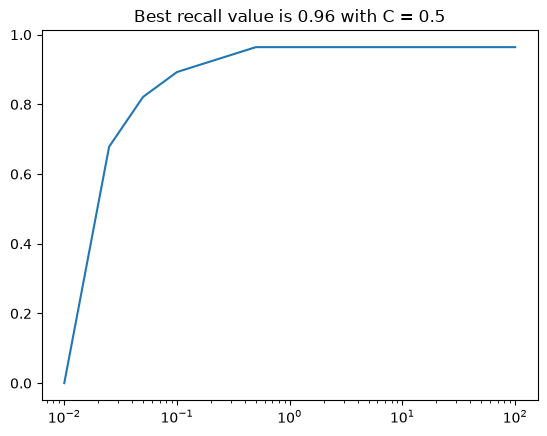

In [8]:
plt.plot(Cs, scores)
plt.xscale('log')

plt.title(f"Best recall value is {max(scores):.2f} with C = {Cs[np.argmax(scores)]}")
plt.show()

In [9]:
model = LogReg(penalty='l1', C=0.5, max_iter=10000, solver='saga', random_state=0)
train_test_model(model, X_train, X_test, y_train, y_test)

C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Accuracy,Precision,Recall
0,0.97193,0.959596,0.959596


In [10]:
model = LogReg(penalty='l1', C=0.5, max_iter=10000, solver='saga', random_state=0)
train_test_model(model, X_train_full, X_test, y_train_full, y_test)

C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\AppEnglish\envs\python26\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Accuracy,Precision,Recall
0,0.97193,0.941748,0.979798


### 2. kNN and k-Folds

<img src="https://i.sstatic.net/m68dT.png" width='500'>

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5,
                                                    random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = kNN(25)
train_test_model(model, X_train, X_test, y_train, y_test)

,Accuracy,Precision,Recall
0,0.950877,0.966667,0.887755


In [12]:
from sklearn.model_selection import GridSearchCV

grid = {
    'metric': ['euclidean', 'manhattan', 'cosine'],
    'weights': ['uniform', 'distance'],
    'n_neighbors': range(3, 26, 2),
}

searcher = GridSearchCV(kNN(), grid,
                        scoring='recall',
                        verbose=1,
                        n_jobs=-1)
searcher.fit(X_train, y_train)

print('Best hyperparameters:', searcher.best_params_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best hyperparameters: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}


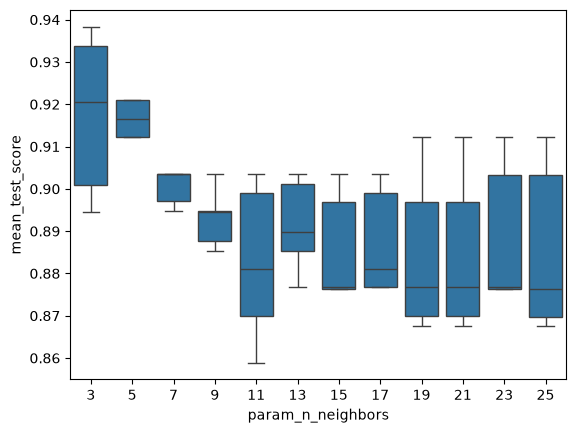

In [13]:
result = searcher.cv_results_
df = pd.DataFrame(result)

sns.boxplot(df, x='param_n_neighbors', y='mean_test_score')
plt.show()

In [14]:
model = kNN(**searcher.best_params_)
train_test_model(model, X_train, X_test, y_train, y_test)

,Accuracy,Precision,Recall
0,0.97193,0.95,0.969388


### 3. Задача

Работаем с тем же датасетом. Используя `GridSearchCV`, для `SVC` выберите ядро из списка `['linear', 'poly', 'rbf']` и регуляризующий параметр из `[0.01, 0.1, 1, 10, 100]`. Для полиномиального ядра также отберите степень из диапазона `range(2, 10)`. Как и прежде, максимизируйте $Recall$.

In [16]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
# your code here


# 2. Пайплайн: масштабирование внутри каждого фолда CV + SVC
pipe_svc = Pipeline([("scaler", StandardScaler()), ("svc", SVC(random_state=0))])

# 3. Сетка параметров: degree имеет смысл только для ядра 'poly'
param_grid = [
    {"svc_kernel": ["linear", "rbf"], 
     "svc_C": [0.01, 0.1, 1, 10, 100]},
    {
        "svc_kernel": ["poly"],
        "svc_C": [0.01, 0.1, 1, 10, 100],
        "svc_degree": range(2, 10),
    },
]

grid_search = GridSearchCV(
    estimator=pipe_svc,
    param_grid=param_grid,
    scoring="recall",
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучший средний Recall на CV: {grid_search.best_score_:.4f}")



Fitting 5 folds for each of 50 candidates, totalling 250 fits
Лучшие параметры: {'svc__C': 1, 'svc__kernel': 'rbf'}
Лучший средний Recall на CV: 0.9433


## Часть 2. Отбор признаков

In [20]:
! pip install -q feature-engine

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif
from feature_engine.selection import DropCorrelatedFeatures

Поработаем с известным датасетом [BACE](https://pubmed.ncbi.nlm.nih.gov/27689393/), содержащим молекулы размеченные как ингибиторы и не-ингибиторы человеческой  
*β-секретазы 1*. Дескрипторы (так хемоинформатики называют признаки) рассчитаны за вас.

In [18]:
! wget -q --no-check-certificate 'https://docs.google.com/uc?export=download&id=1SYdyTbPD01GYcdz7hkyWZGoA5RV44fg7' -O bace.csv

"wget" ­Ґ пў«пҐвбп ў­гваҐ­­Ґ© Ё«Ё ў­Ґи­Ґ©
Є®¬ ­¤®©, ЁбЇ®«­пҐ¬®© Їа®Ја ¬¬®© Ё«Ё Ї ЄҐв­л¬ д ©«®¬.
"id" ­Ґ пў«пҐвбп ў­гваҐ­­Ґ© Ё«Ё ў­Ґи­Ґ©
Є®¬ ­¤®©, ЁбЇ®«­пҐ¬®© Їа®Ја ¬¬®© Ё«Ё Ї ЄҐв­л¬ д ©«®¬.


In [19]:
df = pd.read_csv('bace.csv')
X = df.iloc[:, 4:]
y = df['Class']

FileNotFoundError: [Errno 2] No such file or directory: 'bace.csv'

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
)

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", kNN()),
])
train_test_model(model, X_train, X_test, y_train, y_test)

In [ ]:
pipe = Pipeline([
    ("constant", VarianceThreshold()),
    ("select", SelectKBest(f_classif, k=50)),
    ("scaler", StandardScaler()),
    ("model", kNN()),
])

train_test_model(pipe, X_train, X_test, y_train, y_test)

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC()),
])
train_test_model(model, X_train, X_test, y_train, y_test)

In [ ]:
pipe = Pipeline([
    ("constant", VarianceThreshold().set_output(transform="pandas")),
    ("select", DropCorrelatedFeatures(threshold=0.9)),
    ("scaler", StandardScaler()),
    ("model", SVC()),
])

train_test_model(pipe, X_train, X_test, y_train, y_test)